# CSC17104 · Đồ án cuối kỳ – Notebook 03: Câu hỏi Machine Learning (Q6)
*Người phụ trách: Hoàng Hùng Quân (23120338)*

## Q6 – Ước lượng lương cho tin tuyển dụng không công bố lương

**Câu hỏi.** Có thể ước lượng lương năm của một tin tuyển dụng **chỉ từ thông tin có sẵn lúc đăng tin** (tiêu đề, cấp bậc, loại hợp đồng, bang, remote, nhóm chức năng, ngành, quy mô công ty) với sai số đủ nhỏ để hữu ích không? Những yếu tố nào quyết định mức lương ước lượng?

**Người dùng và quyết định.**
- *Người tìm việc:* 71% tin không ghi lương. Một ước lượng (ví dụ "khoảng $95–120k") giúp quyết định có nên nộp đơn và chuẩn bị đàm phán.
- *Nhà tuyển dụng ở bang có luật minh bạch lương:* cần một khoảng lương tham chiếu khi soạn tin mới.

**Yêu cầu "hữu ích" (đặt trước khi làm).** Mô hình phải tốt hơn rõ rệt so với baseline, và với tin điển hình, sai số tương đối nên khoảng ≤ 20%. Đây là cỡ độ rộng của một khoảng lương thường thấy (median độ rộng khoảng lương trong dữ liệu ≈ 22–24% điểm giữa, xem Q1).

Notebook này cũng chứa **Tổng kết toàn đồ án (mục 3.5)** ở cuối.

In [1]:
import sys, time
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd().parent
sys.path.insert(0, str(ROOT))
from src.data import PROCESSED_DIR, load_job_functions, cluster_id
from src.viz import set_style, SERIES, NEUTRAL, TEXT_2, GRID, usd, pct, note

from sklearn.model_selection import GroupShuffleSplit, GroupKFold, KFold, GridSearchCV, cross_val_score
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.compose import ColumnTransformer, TransformedTargetRegressor
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.decomposition import TruncatedSVD
from sklearn.linear_model import Ridge, LinearRegression
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.dummy import DummyRegressor
from sklearn.metrics import mean_absolute_error, median_absolute_error, r2_score

set_style()
pd.set_option('display.width', 160); pd.set_option('display.max_columns', 30)
pd.set_option('display.float_format', lambda x: f'{x:,.3f}')
SEED = 42

## 1. Dữ liệu và đặc trưng

### 1.1 Lọc dữ liệu
Chỉ các tin có **lương năm hợp lệ** mới có nhãn để huấn luyện/đánh giá. Các tin không có lương dùng ở mục 7 để minh hoạ ứng dụng.

In [2]:
df = pd.read_parquet(PROCESSED_DIR / 'postings_clean.parquet')
df['group'] = cluster_id(df)
steps = [('Bảng đã làm sạch', len(df))]
lab = df[df['annual_salary'].notna()].copy()
steps.append(('Có lương năm hợp lệ (nhãn)', len(lab)))
pd.DataFrame(steps, columns=['bước', 'số dòng'])

,bước,số dòng
0,Bảng đã làm sạch,123849
1,Có lương năm hợp lệ (nhãn),35961


### 1.2 Đặc trưng – chỉ dùng thông tin có lúc đăng tin

| Nhóm | Cột | Xử lý |
|---|---|---|
| Văn bản | `title` | TF-IDF (unigram/bigram) |
| Phân loại | `experience_level`, `work_type`, `state_f` (bang hoặc "toàn quốc/không rõ"), `job_function` (chính), `job_industry`, `company_industry`, `employee_bucket`, `application_type` | One-hot (Ridge) / mã hoá thứ tự + xử lý phân loại gốc (HGB); gộp nhóm hiếm < 20 tin |
| Số / nhị phân | `remote_allowed`, `is_nationwide`, `log_employees` = ln(1 + số nhân viên), `n_functions` | Điền median nếu thiếu, chuẩn hoá |
| Đa nhãn | `fn_*` – 35 cột 0/1, một cột cho mỗi nhóm chức năng (từ `job_skills`, **pivot** dạng dài → dạng rộng) | Giữ nguyên 0/1 |

### 1.3 Các cột **bị loại để tránh rò rỉ dữ liệu (data leakage)**

| Cột | Lý do loại |
|---|---|
| `min_salary`, `med_salary`, `max_salary`, `normalized_salary`, `annual_min/max`, `salary_mid_raw` | Chính là (hoặc tính trực tiếp ra) nhãn |
| `pay_period`, `pay_period_fixed`, `currency`, `salary_status`, `salary_disclosed` | Chỉ tồn tại khi tin **có** lương; tin cần dự đoán (không có lương) không có các cột này. `pay_period` còn gần như tiết lộ mức lương (HOURLY ≈ thấp) |
| `description` | **72% tin có lương ghi luôn số tiền trong mô tả** (notebook 01, mục 2.5) → mô hình sẽ "đọc đáp án" |
| `views`, `applies`, `applies_filled`, `expiry`, `listed_time` | Chỉ biết **sau** khi tin được đăng |
| `job_id`, `company_id`, `company_name`, `job_posting_url`, `group` | Định danh. Với cách chia theo công ty (mục 2), ID công ty ở tập test chưa từng xuất hiện, nên dùng ID chỉ làm mô hình học thuộc |
| `transparency_state` | Suy ra từ `state` (đã có), và tương quan với việc có lương chứ không phải mức lương |

In [3]:
jf = load_job_functions()
fn_wide = pd.crosstab(jf['job_id'], jf['skill_abr']).clip(upper=1).add_prefix('fn_')   # pivot dài → rộng
n0 = len(lab)
lab = lab.merge(fn_wide, left_on='job_id', right_index=True, how='left', validate='1:1')
assert len(lab) == n0, 'merge làm thay đổi số dòng!'
FN = list(fn_wide.columns)
lab[FN] = lab[FN].fillna(0)

def add_features(d):
    d = d.copy()
    d['state_f'] = d['state'].fillna('Toàn quốc/không rõ')
    d['employee_bucket'] = d['employee_bucket'].astype(object).where(d['employee_bucket'].notna(), 'Không rõ').astype(str)
    d['company_industry'] = d['company_industry'].fillna('Không rõ')
    d['log_employees'] = np.log1p(d['employee_count'])
    d['is_nationwide'] = d['is_nationwide'].astype(int)
    return d

lab = add_features(lab)
TEXT = 'title'
CAT = ['experience_level', 'work_type', 'state_f', 'job_function', 'job_industry', 'company_industry', 'employee_bucket', 'application_type']
NUM = ['remote_allowed', 'is_nationwide', 'log_employees', 'n_functions']
FEATS = [TEXT] + CAT + NUM + FN
X_all, y_all, g_all = lab[FEATS], lab['annual_salary'], lab['group']
print(f'{len(FEATS)} cột đầu vào: 1 text + {len(CAT)} phân loại + {len(NUM)} số + {len(FN)} cờ chức năng')
print('Thiếu sau xử lý:', X_all[CAT + FN].isna().sum().sum(), '(phân loại/cờ) |', X_all[NUM].isna().sum().to_dict())

48 cột đầu vào: 1 text + 8 phân loại + 4 số + 35 cờ chức năng
Thiếu sau xử lý: 0 (phân loại/cờ) | {'remote_allowed': 0, 'is_nationwide': 0, 'log_employees': 504, 'n_functions': 534}


## 2. Chia train/test – theo **công ty** (group-based split)

**Vì sao không chia ngẫu nhiên?** Một công ty thường đăng *cùng một vị trí với cùng mức lương ở nhiều địa điểm* (notebook 01: 10% tin là bản sao đa địa điểm). Chia ngẫu nhiên sẽ đưa các bản sao vào cả train lẫn test, và mô hình được "chấm điểm" trên những tin gần như đã thấy, nên kết quả lạc quan giả tạo. Bài toán thực tế là ước lượng lương cho tin của **công ty mà mô hình chưa thấy**, nên dùng `GroupShuffleSplit` theo công ty (80/20). Mọi bước tuning dùng `GroupKFold` theo công ty **trên tập train**.

**Vì sao không chia theo thời gian?** Dữ liệu chỉ phủ ~2 tuần (05–20/04/2024) với lịch cào không đều. Không có xu hướng thời gian đáng kể để mô phỏng "dự đoán tương lai", nên trục tổng quát hoá quan trọng là *công ty mới*. Kiểm tra ở dưới cho thấy phân phối ngày đăng của train/test tương đương.

In [4]:
gss = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=SEED)
tr_idx, te_idx = next(gss.split(X_all, y_all, groups=g_all))
X_tr, X_te = X_all.iloc[tr_idx], X_all.iloc[te_idx]
y_tr, y_te = y_all.iloc[tr_idx], y_all.iloc[te_idx]
g_tr, g_te = g_all.iloc[tr_idx], g_all.iloc[te_idx]
print(f'Train: {len(X_tr):,} tin / {g_tr.nunique():,} công ty | Test: {len(X_te):,} tin / {g_te.nunique():,} công ty')
print('Công ty xuất hiện ở cả hai tập:', len(set(g_tr) & set(g_te)))
chk = pd.DataFrame({
    'train': [y_tr.median(), y_tr.quantile(.25), y_tr.quantile(.75), (lab.iloc[tr_idx]['remote_allowed']).mean(),
              lab.iloc[tr_idx]['listed_date'].median()],
    'test': [y_te.median(), y_te.quantile(.25), y_te.quantile(.75), (lab.iloc[te_idx]['remote_allowed']).mean(),
             lab.iloc[te_idx]['listed_date'].median()]},
    index=['median lương', 'Q1 lương', 'Q3 lương', '% remote', 'ngày đăng (median)'])
chk

Train: 28,358 tin / 8,252 công ty | Test: 7,603 tin / 2,063 công ty
Công ty xuất hiện ở cả hai tập: 0


,train,test
median lương,"81,120.000","87,360.000"
Q1 lương,"52,000.000","55,120.000"
Q3 lương,"124,550.000","132,080.000"
% remote,0.129,0.152
ngày đăng (median),2024-04-18 00:00:00,2024-04-18 00:00:00


## 3. Các mô hình – mọi tiền xử lý nằm trong `Pipeline`

- **Baseline 1 – Median toàn bộ** (`DummyRegressor(strategy="median")`): luôn đoán median của train.
- **Baseline 2 – Theo cấp bậc**: chỉ dùng `experience_level` (trung bình log-lương mỗi cấp). Đây là cách mà người tìm việc hay dùng.
- **Mô hình A – Ridge** (hồi quy tuyến tính có điều chuẩn L2): TF-IDF tiêu đề + one-hot + chuẩn hoá. Phù hợp với dữ liệu văn bản thưa nhiều chiều và dễ diễn giải (mỗi từ trong tiêu đề có một hệ số).
- **Mô hình B – HistGradientBoosting**: cây tăng cường, bắt được tương tác phi tuyến (ví dụ "Senior" ở bang CA khác ở bang TX). Văn bản được nén bằng TF-IDF → TruncatedSVD (vì cây không làm việc tốt với ma trận thưa hàng chục nghìn chiều), biến phân loại dùng xử lý phân loại gốc của HGB.

Cả bốn mô hình học trên **log(lương)** qua `TransformedTargetRegressor`: lương lệch phải mạnh, và sai số *tương đối* quan trọng hơn sai số tuyệt đối (sai $10k với việc $40k nghiêm trọng hơn với việc $200k). Dự đoán được đổi về USD trước khi tính metric.

In [ ]:
def log_target(reg):
    return TransformedTargetRegressor(regressor=reg, func=np.log, inverse_func=np.exp)

baseline_median = DummyRegressor(strategy='median')
baseline_level = log_target(Pipeline([
    ('pre', ColumnTransformer([('lvl', OneHotEncoder(handle_unknown='ignore'), ['experience_level'])])),
    ('m', LinearRegression())]))

pre_linear = ColumnTransformer([
    ('title', TfidfVectorizer(ngram_range=(1, 2), min_df=3, sublinear_tf=True), TEXT),
    ('cat', OneHotEncoder(handle_unknown='infrequent_if_exist', min_frequency=20), CAT),
    ('num', make_pipeline(SimpleImputer(strategy='median'), StandardScaler()), NUM),
    ('fn', 'passthrough', FN)])
ridge = log_target(Pipeline([('pre', pre_linear), ('m', Ridge(alpha=1.0))]))

N_SVD = 100
pre_tree = ColumnTransformer([
    ('title', Pipeline([('tfidf', TfidfVectorizer(ngram_range=(1, 2), min_df=3, sublinear_tf=True)),
                        ('svd', TruncatedSVD(n_components=N_SVD, random_state=SEED))]), TEXT),
    ('cat', OrdinalEncoder(handle_unknown='use_encoded_value', unknown_value=-1, encoded_missing_value=-1,
                           min_frequency=20, max_categories=120), CAT),
    ('num', 'passthrough', NUM),
    ('fn', 'passthrough', FN)])
cat_mask = [False] * N_SVD + [True] * len(CAT) + [False] * (len(NUM) + len(FN))
hgb = log_target(Pipeline([('pre', pre_tree),
                           ('m', HistGradientBoostingRegressor(max_iter=400, categorical_features=cat_mask,
                                                               early_stopping=False, random_state=SEED))]))
ridge

,"regressor regressor: object, default=NoneRegressor object such as derived from:class:`~sklearn.base.RegressorMixin`. This regressor willautomatically be cloned each time prior to fitting. If `regressor isNone`, :class:`~sklearn.linear_model.LinearRegression` is created and used.","Pipeline(step...m', Ridge())])"
,"func func: function, default=NoneFunction to apply to `y` before passing to :meth:`fit`. Cannot be setat the same time as `transformer`. If `func is None`, the function used will bethe identity function. If `func` is set, `inverse_func` also needs to beprovided. The function needs to return a 2-dimensional array.",<ufunc 'log'>
,"inverse_func inverse_func: function, default=NoneFunction to apply to the prediction of the regressor. Cannot be set atthe same time as `transformer`. The inverse function is used to returnpredictions to the same space of the original training labels. If`inverse_func` is set, `func` also needs to be provided. The inversefunction needs to return a 2-dimensional array.",<ufunc 'exp'>
,"transformer transformer: object, default=NoneEstimator object such as derived from:class:`~sklearn.base.TransformerMixin`. Cannot be set at the same timeas `func` and `inverse_func`. If `transformer is None` as well as`func` and `inverse_func`, the transformer will be an identitytransformer. Note that the transformer will be cloned during fitting.Also, the transformer is restricting `y` to be a numpy array.",None
,"check_inverse check_inverse: bool, default=TrueWhether to check that `transform` followed by `inverse_transform`or `func` followed by `inverse_func` leads to the original targets.",True
,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('pre', ...), ('m', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to

## 4. Tuning bằng cross-validation **chỉ trên tập train**

`GridSearchCV` với `GroupKFold(5)` theo công ty. Tiêu chí chọn: **MAE (USD)**. Lý do chọn MAE:
- Đơn vị là **đô la** nên dễ hiểu ("sai trung bình $X").
- Ít bị chi phối bởi vài tin lương cực cao so với RMSE (phân phối lương có đuôi dài).
- Bổ sung **MdAPE** (median sai số %) và **% tin sai ≤ 20%** để đánh giá theo tiêu chí "hữu ích" đã đặt ra.

(Accuracy hay R² trên thang USD không phù hợp: đây là hồi quy, và R² bị kéo mạnh bởi vài giá trị lương rất cao.)

In [6]:
cv = GroupKFold(n_splits=5)
grids = {
    'Ridge': (ridge, {'regressor__m__alpha': [0.3, 1, 3, 10],
                      'regressor__pre__title__ngram_range': [(1, 1), (1, 2)]}),
    'HistGradientBoosting': (hgb, {'regressor__m__learning_rate': [0.05, 0.1],
                                   'regressor__m__max_leaf_nodes': [31, 63]}),
}
searches = {}
for name, (est, grid) in grids.items():
    t = time.time()
    gs = GridSearchCV(est, grid, cv=cv, scoring='neg_mean_absolute_error', n_jobs=2, refit=True)
    gs.fit(X_tr, y_tr, groups=g_tr)
    searches[name] = gs
    res = pd.DataFrame(gs.cv_results_)[['params', 'mean_test_score', 'std_test_score']]
    res['CV MAE'] = -res['mean_test_score']; res['std'] = res['std_test_score']
    print(f'\n{name}: {time.time() - t:.0f}s | tốt nhất: {gs.best_params_} | CV MAE = ${-gs.best_score_:,.0f}')
    display(res[['params', 'CV MAE', 'std']].sort_values('CV MAE').style.format({'CV MAE': '${:,.0f}', 'std': '${:,.0f}'}))


Ridge: 41s | tốt nhất: {'regressor__m__alpha': 3, 'regressor__pre__title__ngram_range': (1, 2)} | CV MAE = $24,308


,params,CV MAE,std
5,"{'regressor__m__alpha': 3, 'regressor__pre__title__ngram_range': (1, 2)}","$24,308",$344
3,"{'regressor__m__alpha': 1, 'regressor__pre__title__ngram_range': (1, 2)}","$24,320",$272
2,"{'regressor__m__alpha': 1, 'regressor__pre__title__ngram_range': (1, 1)}","$24,846",$441
4,"{'regressor__m__alpha': 3, 'regressor__pre__title__ngram_range': (1, 1)}","$24,881",$455
1,"{'regressor__m__alpha': 0.3, 'regressor__pre__title__ngram_range': (1, 2)}","$24,995",$292
7,"{'regressor__m__alpha': 10, 'regressor__pre__title__ngram_range': (1, 2)}","$25,052",$483
0,"{'regressor__m__alpha': 0.3, 'regressor__pre__title__ngram_range': (1, 1)}","$25,102",$468
6,"{'regressor__m__alpha': 10, 'regressor__pre__title__ngram_range': (1, 1)}","$25,412",$517



HistGradientBoosting: 497s | tốt nhất: {'regressor__m__learning_rate': 0.05, 'regressor__m__max_leaf_nodes': 63} | CV MAE = $24,677


,params,CV MAE,std
1,"{'regressor__m__learning_rate': 0.05, 'regressor__m__max_leaf_nodes': 63}","$24,677",$610
3,"{'regressor__m__learning_rate': 0.1, 'regressor__m__max_leaf_nodes': 63}","$24,904",$577
0,"{'regressor__m__learning_rate': 0.05, 'regressor__m__max_leaf_nodes': 31}","$24,918",$582
2,"{'regressor__m__learning_rate': 0.1, 'regressor__m__max_leaf_nodes': 31}","$24,964",$593


In [7]:
cv_base = {}
for name, est in [('Baseline: median', baseline_median), ('Baseline: theo cấp bậc', baseline_level)]:
    s = cross_val_score(est, X_tr, y_tr, groups=g_tr, cv=cv, scoring='neg_mean_absolute_error')
    cv_base[name] = -s.mean()
cv_table = pd.Series({**cv_base, **{k: -v.best_score_ for k, v in searches.items()}}, name='CV MAE (train, GroupKFold)')
best_name = cv_table.drop(list(cv_base)).idxmin()
print('Mô hình được chọn theo CV:', best_name)
cv_table.map('${:,.0f}'.format).to_frame()

Mô hình được chọn theo CV: Ridge


,"CV MAE (train, GroupKFold)"
Baseline: median,"$42,511"
Baseline: theo cấp bậc,"$35,877"
Ridge,"$24,308"
HistGradientBoosting,"$24,677"


**Minh hoạ vì sao phải chia theo công ty.** Cùng mô hình Ridge tốt nhất, đánh giá bằng `KFold` ngẫu nhiên thay vì `GroupKFold`:

In [8]:
best_ridge = searches['Ridge'].best_estimator_
mae_random = -cross_val_score(best_ridge, X_tr, y_tr, cv=KFold(5, shuffle=True, random_state=SEED), scoring='neg_mean_absolute_error').mean()
mae_group = -searches['Ridge'].best_score_
print(f'CV MAE – KFold ngẫu nhiên: ${mae_random:,.0f} | GroupKFold theo công ty: ${mae_group:,.0f} '
      f'→ chia ngẫu nhiên lạc quan hơn {1 - mae_random / mae_group:.0%}')

CV MAE – KFold ngẫu nhiên: $22,738 | GroupKFold theo công ty: $24,308 → chia ngẫu nhiên lạc quan hơn 6%


## 5. Đánh giá trên tập test – **một lần duy nhất**
Mô hình đã được chọn bằng CV ở trên; tập test chỉ dùng để báo cáo. Tất cả mô hình được fit lại trên toàn bộ train (GridSearchCV đã `refit=True`) và báo cáo cùng lúc để so sánh.

In [9]:
def metrics(y, p):
    ape = np.abs(p - y) / y
    return {'MAE': mean_absolute_error(y, p), 'MedAE': median_absolute_error(y, p), 'MdAPE': np.median(ape),
            '% sai ≤ 20%': (ape <= 0.20).mean(), 'R² (log)': r2_score(np.log(y), np.log(p))}

final = {'Baseline: median': baseline_median.fit(X_tr, y_tr),
         'Baseline: theo cấp bậc': baseline_level.fit(X_tr, y_tr),
         **{k: v.best_estimator_ for k, v in searches.items()}}
preds = {k: m.predict(X_te) for k, m in final.items()}
test_table = pd.DataFrame({k: metrics(y_te.to_numpy(), p) for k, p in preds.items()}).T
test_table.style.format({'MAE': '${:,.0f}', 'MedAE': '${:,.0f}', 'MdAPE': '{:.1%}', '% sai ≤ 20%': '{:.1%}', 'R² (log)': '{:.3f}'})

,MAE,MedAE,MdAPE,% sai ≤ 20%,R² (log)
Baseline: median,"$44,811","$33,880",41.0%,23.8%,-0.012
Baseline: theo cấp bậc,"$37,899","$25,937",32.1%,31.3%,0.229
Ridge,"$25,082","$15,856",19.2%,51.7%,0.651
HistGradientBoosting,"$25,291","$16,243",19.3%,51.4%,0.644


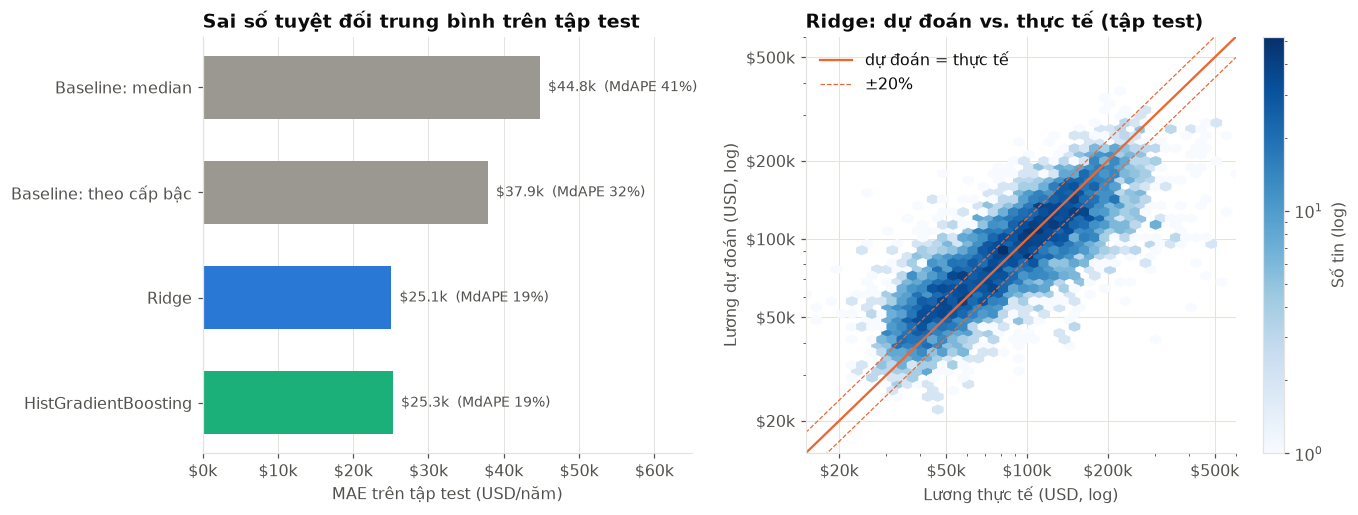

In [10]:
best = final[best_name]; p_best = preds[best_name]
fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.8), gridspec_kw={'width_ratios': [1, 1.1]})
ax = axes[0]
order = list(test_table.index)
colors = [NEUTRAL, NEUTRAL, SERIES[0], SERIES[2]]
ax.barh(order, test_table['MAE'], color=colors, height=0.6)
for i, (m, a) in enumerate(zip(test_table['MAE'], test_table['MdAPE'])):
    ax.text(m, i, f'  ${m/1000:.1f}k  (MdAPE {a:.0%})', va='center', fontsize=9, color=TEXT_2)
ax.xaxis.set_major_formatter(usd); ax.set_xlim(0, test_table['MAE'].max() * 1.45)
ax.invert_yaxis(); ax.grid(axis='y', visible=False)
ax.set_xlabel('MAE trên tập test (USD/năm)'); ax.set_title('Sai số tuyệt đối trung bình trên tập test')
ax = axes[1]
hb = ax.hexbin(y_te, p_best, gridsize=45, xscale='log', yscale='log', cmap='Blues', mincnt=1, bins='log')
lim = [15_000, 600_000]
ax.plot(lim, lim, color=SERIES[1], linewidth=1.5, label='dự đoán = thực tế')
ax.plot(lim, [l * 1.2 for l in lim], color=SERIES[1], linewidth=0.8, linestyle='--', label='±20%')
ax.plot(lim, [l / 1.2 for l in lim], color=SERIES[1], linewidth=0.8, linestyle='--')
ax.set_xlim(lim); ax.set_ylim(lim)
for a in (ax.xaxis, ax.yaxis):
    a.set_major_formatter(usd); a.set_minor_formatter(plt.NullFormatter())
ax.set_xticks([20_000, 50_000, 100_000, 200_000, 500_000]); ax.set_yticks([20_000, 50_000, 100_000, 200_000, 500_000])
ax.set_xlabel('Lương thực tế (USD, log)'); ax.set_ylabel('Lương dự đoán (USD, log)')
ax.set_title(f'{best_name}: dự đoán vs. thực tế (tập test)'); ax.legend(loc='upper left')
fig.colorbar(hb, ax=ax, label='Số tin (log)')
plt.tight_layout(); plt.show()

## 6. Phân tích lỗi – mô hình sai ở đâu?

In [11]:
err = lab.iloc[te_idx][['title', 'company_name', 'experience_level', 'work_type', 'pay_period_fixed', 'remote_allowed',
                        'job_function', 'state_f', 'annual_salary']].copy()
err['pred'] = p_best
err['ape'] = (err['pred'] - err['annual_salary']).abs() / err['annual_salary']
err['signed'] = (err['pred'] - err['annual_salary']) / err['annual_salary']
err['decile'] = pd.qcut(err['annual_salary'], 10, labels=[f'D{i}' for i in range(1, 11)])

def summarize(by):
    return err.groupby(by, observed=True).agg(n=('ape', 'size'), MdAPE=('ape', 'median'),
                                              sai_le_20=('ape', lambda s: (s <= .2).mean()),
                                              thien_lech=('signed', 'median'))
lvl = summarize('experience_level').sort_values('MdAPE')
pp = summarize('pay_period_fixed')
display(lvl.style.format({'MdAPE': '{:.1%}', 'sai_le_20': '{:.1%}', 'thien_lech': '{:+.1%}'}))
display(pp.style.format({'MdAPE': '{:.1%}', 'sai_le_20': '{:.1%}', 'thien_lech': '{:+.1%}'}))

,n,MdAPE,sai_le_20,thien_lech
experience_level,,,,
Director,291,16.4%,59.8%,+5.6%
Internship,52,17.4%,55.8%,+11.2%
Mid-Senior level,2691,17.9%,54.1%,+2.0%
Associate,751,19.1%,51.5%,+1.1%
Entry level,1745,19.3%,51.7%,+3.8%
Unknown,1982,21.3%,47.8%,-3.5%
Executive,91,26.1%,40.7%,+5.1%


,n,MdAPE,sai_le_20,thien_lech
pay_period_fixed,,,,
HOURLY,2974,20.0%,49.9%,+6.8%
MONTHLY,93,26.6%,40.9%,+8.3%
WEEKLY,49,10.1%,71.4%,-8.9%
YEARLY,4487,18.7%,53.0%,-1.8%


Thiên lệch median: thập phân vị thấp nhất +34.1%, cao nhất -28.7%


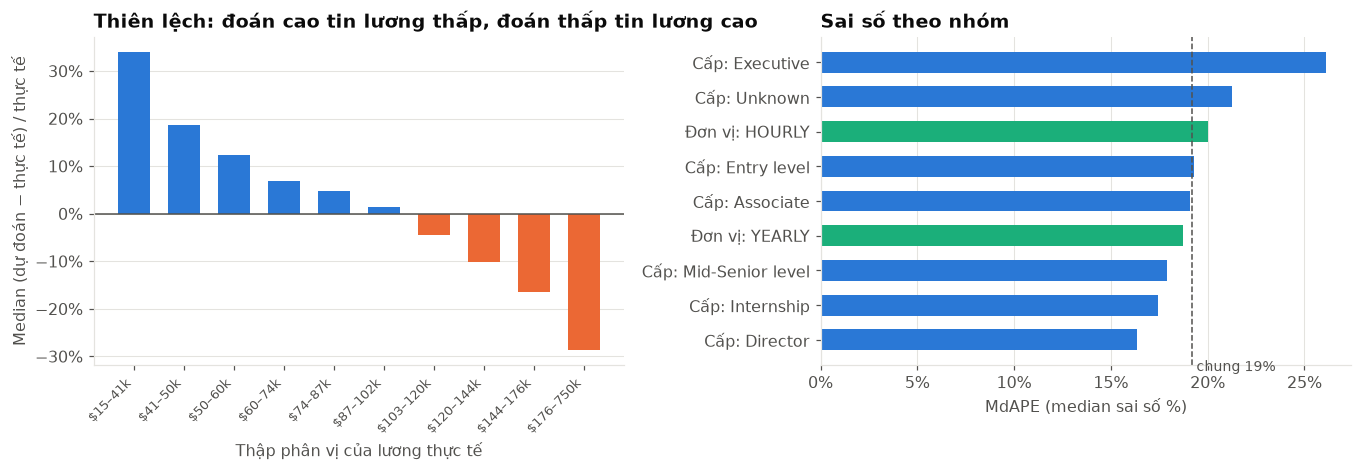

In [12]:
dec = summarize('decile')
dec['range'] = err.groupby('decile', observed=True)['annual_salary'].agg(lambda s: f'${s.min()/1000:.0f}–{s.max()/1000:.0f}k')
print(f"Thiên lệch median: thập phân vị thấp nhất {dec['thien_lech'].iloc[0]:+.1%}, cao nhất {dec['thien_lech'].iloc[-1]:+.1%}")
fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.4))
ax = axes[0]
x = np.arange(len(dec))
ax.bar(x, dec['thien_lech'], color=[SERIES[0] if v > 0 else SERIES[1] for v in dec['thien_lech']], width=0.65)
ax.axhline(0, color=TEXT_2, linewidth=1)
ax.set_xticks(x); ax.set_xticklabels(dec['range'], rotation=45, ha='right', fontsize=8.5)
ax.yaxis.set_major_formatter(pct)
ax.set_xlabel('Thập phân vị của lương thực tế'); ax.set_ylabel('Median (dự đoán − thực tế) / thực tế')
ax.set_title('Thiên lệch: đoán cao tin lương thấp, đoán thấp tin lương cao'); ax.grid(axis='x', visible=False)
ax = axes[1]
seg = pd.concat([lvl['MdAPE'].rename(lambda s: f'Cấp: {s}'), pp.loc[['HOURLY', 'YEARLY'], 'MdAPE'].rename(lambda s: f'Đơn vị: {s}')])
seg = seg.sort_values()
ax.barh(seg.index, seg.values, color=[SERIES[2] if 'Đơn vị' in s else SERIES[0] for s in seg.index], height=0.6)
ax.axvline(np.median(err['ape']), color=TEXT_2, linestyle='--', linewidth=1)
ax.text(np.median(err['ape']), -0.9, f" chung {np.median(err['ape']):.0%}", color=TEXT_2, fontsize=9)
ax.xaxis.set_major_formatter(pct); ax.set_xlabel('MdAPE (median sai số %)')
ax.set_title('Sai số theo nhóm'); ax.grid(axis='y', visible=False)
plt.tight_layout(); plt.show()

In [13]:
pd.set_option('display.max_colwidth', 60)
worst = err.sort_values('ape', ascending=False).head(10)
worst[['title', 'experience_level', 'work_type', 'pay_period_fixed', 'state_f', 'annual_salary', 'pred', 'ape']] \
    .style.format({'annual_salary': '${:,.0f}', 'pred': '${:,.0f}', 'ape': '{:.0%}'})

,title,experience_level,work_type,pay_period_fixed,state_f,annual_salary,pred,ape
66401,Principal Electrical Engineer,Unknown,Full-time,YEARLY,NY,"$25,000","$149,350",497%
8956,"In Seat Beer Vendor, Truist Park",Unknown,Full-time,HOURLY,GA,"$15,080","$58,879",290%
118137,Sales Consultant,Unknown,Contract,YEARLY,NJ,"$20,000","$76,570",283%
6795,Head Volley Ball Coach,Director,Full-time,YEARLY,OK,"$25,000","$93,946",276%
6288,Director,Unknown,Full-time,YEARLY,MO,"$48,000","$175,498",266%
113254,First Class Hosts- Birmingham New Street,Mid-Senior level,Full-time,YEARLY,TX,"$24,748","$89,441",261%
10803,BI Developer,Mid-Senior level,Full-time,HOURLY,IL,"$29,120","$105,180",261%
118406,Clinical Supervisor - Deaf Services,Mid-Senior level,Full-time,YEARLY,WA,"$25,000","$89,436",258%
3422,"In-Seat Runner, American Family Field",Unknown,Temporary,HOURLY,WI,"$16,224","$54,743",237%
98839,Physician Liaision - Owensboro Surgery Center,Mid-Senior level,Full-time,HOURLY,KY,"$39,520","$132,324",235%


## 7. Diễn giải mô hình

**Permutation importance theo nhóm đặc trưng** (trên tập test): xáo trộn ngẫu nhiên giá trị của một nhóm đặc trưng giữa các tin rồi đo MAE tăng bao nhiêu – càng tăng nhiều, mô hình càng dựa vào nhóm đó. 35 cờ chức năng `fn_*` được xáo **cùng lúc** như một nhóm vì chúng mô tả cùng một thông tin.

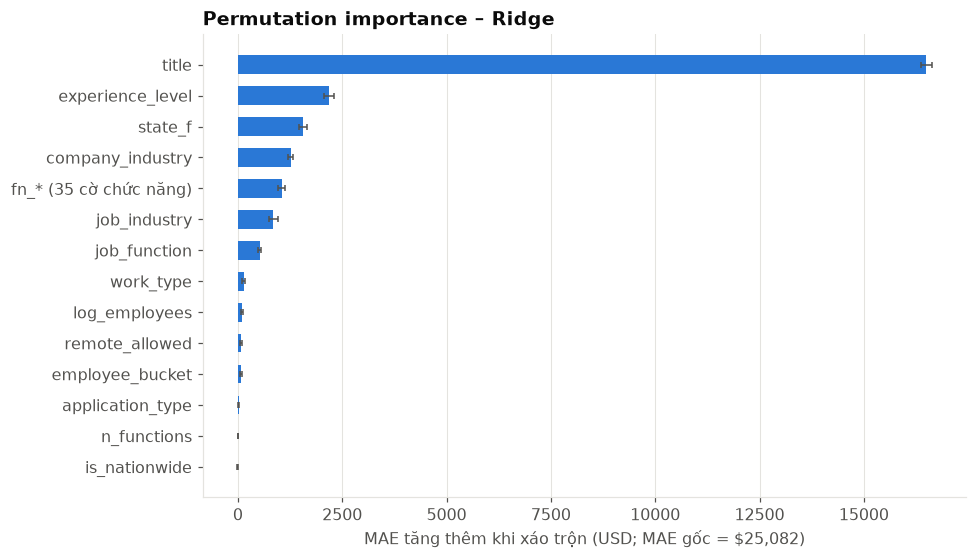

,MAE tăng (USD),std
nhóm đặc trưng,,
title,"$16,492",$132
experience_level,"$2,174",$118
state_f,"$1,566",$91
company_industry,"$1,265",$61
fn_* (35 cờ chức năng),"$1,048",$75
job_industry,$853,$97
job_function,$519,$47
work_type,$137,$28
log_employees,$99,$16


In [14]:
groups_imp = {c: [c] for c in [TEXT] + CAT + NUM}
groups_imp['fn_* (35 cờ chức năng)'] = FN
rng = np.random.default_rng(SEED)
base_mae = mean_absolute_error(y_te, best.predict(X_te))
rows = []
for name, cols in groups_imp.items():
    inc = []
    for r in range(5):
        Xp = X_te.copy()
        perm = rng.permutation(len(Xp))
        Xp[cols] = Xp[cols].to_numpy()[perm]
        inc.append(mean_absolute_error(y_te, best.predict(Xp)) - base_mae)
    rows.append({'nhóm đặc trưng': name, 'MAE tăng (USD)': np.mean(inc), 'std': np.std(inc)})
imp = pd.DataFrame(rows).sort_values('MAE tăng (USD)', ascending=False).set_index('nhóm đặc trưng')
fig, ax = plt.subplots(figsize=(9, 5.2))
ax.barh(imp.index[::-1], imp['MAE tăng (USD)'][::-1], xerr=imp['std'][::-1], color=SERIES[0], height=0.6,
        error_kw=dict(ecolor=TEXT_2, capsize=2, linewidth=1))
ax.set_xlabel(f'MAE tăng thêm khi xáo trộn (USD; MAE gốc = ${base_mae:,.0f})')
ax.set_title(f'Permutation importance – {best_name}'); ax.grid(axis='y', visible=False)
plt.tight_layout(); plt.show()
imp.style.format('${:,.0f}')

**Từ nào trong tiêu đề kéo lương lên/xuống?** Mô hình Ridge cho phép đọc trực tiếp hệ số của từng từ (trên thang log-lương; hệ số 0.1 ≈ +10.5% lương khi giữ nguyên các yếu tố khác).

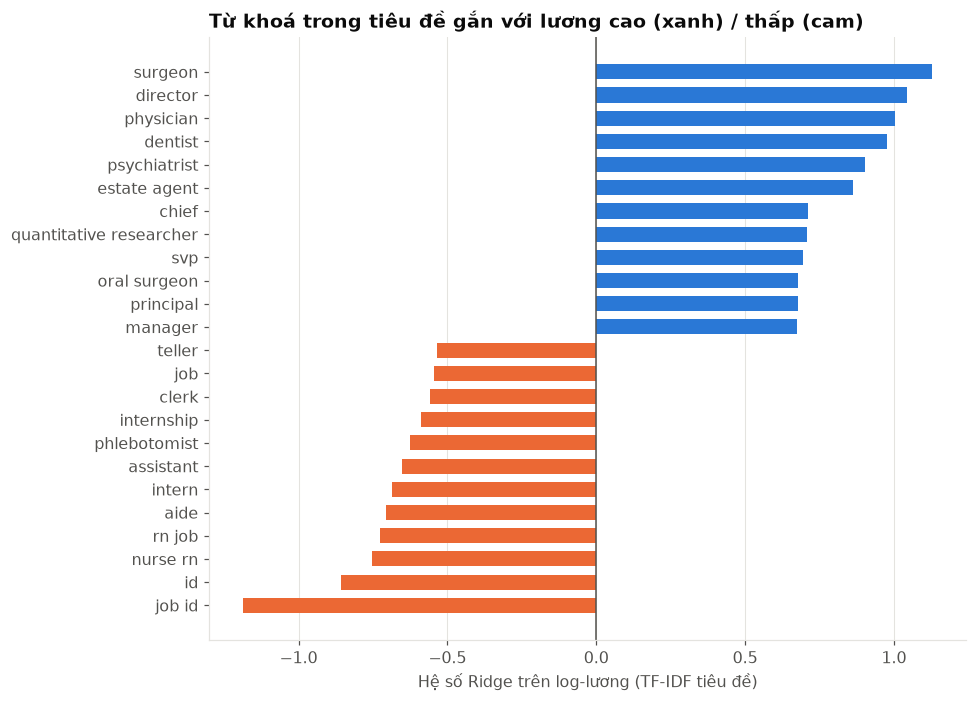

In [15]:
rp = searches['Ridge'].best_estimator_.regressor_
vocab = rp.named_steps['pre'].named_transformers_['title'].get_feature_names_out()
coefs = pd.Series(rp.named_steps['m'].coef_[:len(vocab)], index=vocab)
top = pd.concat([coefs.nlargest(12), coefs.nsmallest(12)]).sort_values()
fig, ax = plt.subplots(figsize=(9, 6.5))
ax.barh(top.index, top.values, color=[SERIES[0] if v > 0 else SERIES[1] for v in top.values], height=0.65)
ax.axvline(0, color=TEXT_2, linewidth=1)
ax.set_xlabel('Hệ số Ridge trên log-lương (TF-IDF tiêu đề)')
ax.set_title('Từ khoá trong tiêu đề gắn với lương cao (xanh) / thấp (cam)'); ax.grid(axis='y', visible=False)
plt.tight_layout(); plt.show()

**Kiểm tra token lạ "job id".** Từ "job id" có hệ số âm lớn nhất – không phải một nghề. Xem những tin nào có cụm này:

In [16]:
jid = lab[lab['title'].str.contains(r'\bjob id\b', case=False, regex=True)]
print(f"{len(jid):,} tin có 'Job ID' trong tiêu đề, từ {jid['company_name'].nunique()} công ty; median lương ${jid['annual_salary'].median():,.0f}")
print(jid['company_name'].value_counts().head(5).to_string())
print(jid['title'].head(5).to_string())

104 tin có 'Job ID' trong tiêu đề, từ 1 công ty; median lương $26,538
company_name
Health Carousel Nursing & Allied Health    104
7845    ST Travel Surgical Technologist - Job Id: JO03715772
7985                     NICU Travel RN - Job Id: JO03715751
7987                         Travel RRT - Job Id: JO03715761
7988      X-Ray Travel Rad Technologist - Job Id: JO03715814
7989                       ER Travel RN - Job Id: JO03715746


## 8. Ứng dụng: ước lượng lương cho tin **không** công bố lương
Áp dụng mô hình cho các tin không có lương. **Lệch phân phối (distribution shift):** tin không công bố lương khác tin có lương (ít ở bang có luật hơn, nhiều cấp bậc "Unknown" hơn…), nên sai số thực tế trên nhóm này có thể lớn hơn sai số trên tập test.

In [17]:
unl = df[df['annual_salary'].isna() & (df['salary_status'] == 'not_disclosed')].copy()
unl = unl.merge(fn_wide, left_on='job_id', right_index=True, how='left')
unl[FN] = unl[FN].fillna(0)
unl = add_features(unl)
unl['pred'] = best.predict(unl[FEATS])
print(f'Số tin không có lương được ước lượng: {len(unl):,}')
shift = pd.DataFrame({
    'Có lương (huấn luyện)': [lab['transparency_state'].mean(), (lab['experience_level'] == 'Unknown').mean(), lab['remote_allowed'].mean()],
    'Không có lương': [unl['transparency_state'].mean(), (unl['experience_level'] == 'Unknown').mean(), unl['remote_allowed'].mean()]},
    index=['% ở bang có luật', '% cấp bậc Unknown', '% remote'])
display((shift * 100).round(1))

ds = unl[unl['title'].str.contains(r'\bdata (?:scientist|analyst|engineer)\b', case=False, regex=True)].copy()
ds['role'] = ds['title'].str.extract(r'(?i)\bdata (scientist|analyst|engineer)\b')[0].str.lower().map(
    {'scientist': 'Data Scientist', 'analyst': 'Data Analyst', 'engineer': 'Data Engineer'})
summary = ds.groupby(['role', 'experience_level'])['pred'].agg(['size', 'median']).query('size >= 15')
summary.columns = ['số tin', 'lương ước lượng (median)']
display(summary.style.format({'lương ước lượng (median)': '${:,.0f}'}))

Số tin không có lương được ước lượng: 87,776


,Có lương (huấn luyện),Không có lương
% ở bang có luật,36.300,15.100
% cấp bậc Unknown,22.400,24.300
% remote,13.400,11.800


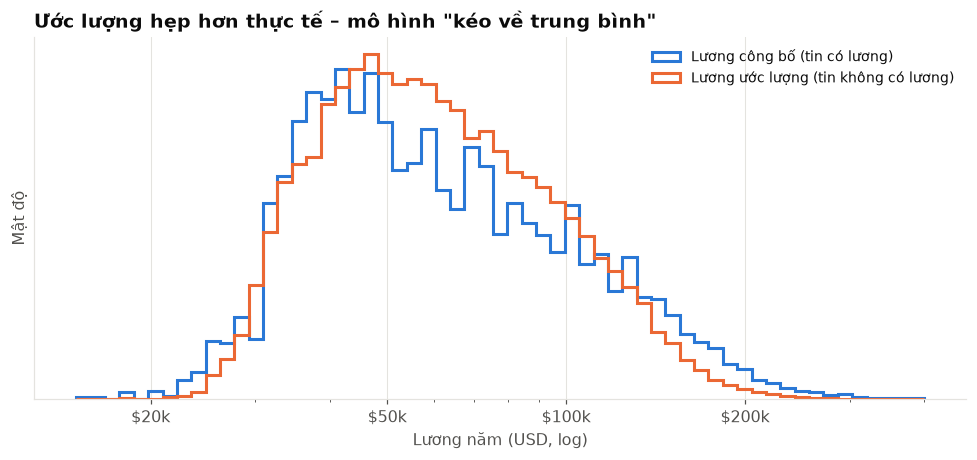

Median lương công bố: $82,500 | median ước lượng cho tin không có lương: $74,918
Độ lệch chuẩn log: thực tế 0.56 vs ước lượng 0.46
Độ lệch chuẩn log của dự đoán trên tập test: 0.45 (thực tế test: 0.56)


In [18]:
fig, ax = plt.subplots(figsize=(9, 4.3))
bins = np.logspace(np.log10(15_000), np.log10(400_000), 60)
ax.hist(lab['annual_salary'], bins=bins, density=True, histtype='step', linewidth=2, color=SERIES[0], label='Lương công bố (tin có lương)')
ax.hist(unl['pred'], bins=bins, density=True, histtype='step', linewidth=2, color=SERIES[1], label='Lương ước lượng (tin không có lương)')
ax.set_xscale('log'); ax.set_xticks([20_000, 50_000, 100_000, 200_000])
ax.xaxis.set_major_formatter(usd); ax.xaxis.set_minor_formatter(plt.NullFormatter()); ax.set_yticks([])
ax.set_xlabel('Lương năm (USD, log)'); ax.set_ylabel('Mật độ')
ax.set_title('Ước lượng hẹp hơn thực tế – mô hình "kéo về trung bình"')
ax.legend(loc='upper right', fontsize=9)
plt.tight_layout(); plt.show()
print(f"Median lương công bố: ${lab['annual_salary'].median():,.0f} | median ước lượng cho tin không có lương: ${unl['pred'].median():,.0f}")
print(f"Độ lệch chuẩn log: thực tế {np.log(lab['annual_salary']).std():.2f} vs ước lượng {np.log(unl['pred']).std():.2f}")
print(f"Độ lệch chuẩn log của dự đoán trên tập test: {np.log(p_best).std():.2f} (thực tế test: {np.log(y_te).std():.2f})")

## 9. Kết luận Q6

**Trả lời: Được, ở mức "ước lượng khoảng", chưa đủ để thay con số thật.**

- **Mô hình chọn theo CV:** Ridge (α = 3, TF-IDF unigram + bigram), CV MAE **$24,308**. HistGradientBoosting gần như ngang (CV MAE $24,677). Nhóm chọn Ridge vì đơn giản hơn, huấn luyện nhanh hơn nhiều lần và diễn giải được trực tiếp.
- **Trên tập test** (7,603 tin của 2,063 công ty mô hình chưa từng thấy): MAE **$25,082**, tức giảm **44%** so với baseline median ($44,811) và **34%** so với baseline "theo cấp bậc" ($37,899). Median sai số tuyệt đối là **$15,856**; **MdAPE = 19.2%**; **51.7%** số tin được dự đoán sai ≤ 20%; R² trên thang log = 0.65.
- **So với tiêu chí đặt ra** (sai số tương đối khoảng ≤ 20% cho tin điển hình): đạt sát ngưỡng. Với một nửa số tin, khoảng "dự đoán ± 20%" chứa lương thật. Đủ để người tìm việc biết vị trí thuộc tầm $60k hay $120k, nhưng **chưa đủ chính xác để dùng làm con số đàm phán**.
- **Chia theo công ty là cần thiết:** đánh giá bằng KFold ngẫu nhiên cho MAE thấp hơn 6% – lạc quan giả tạo do bản sao đa địa điểm.

**Mô hình sai ở đâu?**
- **Kéo về trung bình:** đoán cao +34% với 10% tin lương thấp nhất và đoán thấp −29% với 10% tin lương cao nhất. Trên tập test, độ phân tán của dự đoán (độ lệch chuẩn log 0.45) hẹp hơn thực tế (0.56). Mô hình hồi quy đặc trưng như vậy vì tiêu đề không chứa đủ thông tin để phân biệt các trường hợp cực đoan.
- **Nhóm khó:** Executive (MdAPE 26%), cấp bậc Unknown (21%), việc trả theo giờ (20%). Nhóm dễ: Director (16%), Mid-Senior (18%).
- **Các lỗi lớn nhất thường là *dữ liệu sai* chứ không phải *mô hình sai*:** ví dụ "Principal Electrical Engineer" công bố $25,000/năm, "Director" $48,000/năm – nhiều khả năng là lỗi đơn vị chưa bắt được.
- **Token "job id":** có hệ số âm lớn nhất vì cả 104 tin chứa cụm này đến từ **một công ty** (y tá du lịch "Health Carousel"), ghi lương MONTHLY với median chỉ $26.5k/năm – rất có thể là lương *theo tuần* bị ghi nhầm thành *theo tháng*. Mô hình đã học thuộc *cách đặt tiêu đề* của một công ty. Chia theo công ty ngăn chuyện này làm sai lệch điểm test, nhưng đây là lời nhắc rằng còn lỗi đơn vị mà quy tắc làm sạch chưa bắt được.

**Yếu tố nào quyết định lương?** Theo permutation importance, **tiêu đề** quan trọng vượt trội (xáo trộn → MAE tăng **$16,492**), sau đó là cấp bậc (+$2,174), bang (+$1,566), ngành công ty (+$1,265) và các cờ chức năng (+$1,048). Remote, quy mô công ty và hình thức nộp đơn gần như không thêm thông tin *khi đã biết tiêu đề* (< $100). Điều này không mâu thuẫn với Q2/Q4: hiệu ứng remote và quy mô có thật nhưng nhỏ, và phần lớn đã được phản ánh qua tiêu đề/chức năng. Từ khoá kéo lương lên: *surgeon, director, physician, dentist, psychiatrist, chief, quantitative researcher, principal*. Kéo lương xuống: *teller, clerk, intern, aide, phlebotomist, assistant*.

**Ứng dụng.** Mô hình ước lượng lương cho 87,776 tin không công bố, median **$74,918** (thấp hơn median $82,500 của tin có lương). Kết quả này **phải đọc thận trọng** vì có lệch phân phối: chỉ 15.1% tin không có lương nằm ở bang có luật (tin có lương: 36.3%). Với các vị trí gần với ngành của nhóm, mô hình ước lượng ví dụ Data Analyst Entry ≈ $87k, Data Engineer Mid-Senior ≈ $145k, Data Scientist Mid-Senior ≈ $161k (lương cơ bản công bố ở Mỹ, 04/2024).

**Hạn chế.** (1) Nhãn là lương *công bố*, có nhiễu (lỗi đơn vị còn sót). (2) Tin có lương không phải mẫu ngẫu nhiên của mọi tin, nên sai số trên tin không có lương có thể lớn hơn sai số test. (3) Không dùng mô tả công việc (do leakage). Nếu xoá các con số tiền khỏi mô tả trước, mô tả có thể thêm nhiều thông tin (kỹ năng, yêu cầu kinh nghiệm). (4) Mô hình cho *một con số*, trong khi người dùng cần *một khoảng*. Hồi quy phân vị (quantile regression) sẽ phù hợp hơn.

---
# Tổng kết đồ án (mục 3.5)

## Phát hiện chính
1. **Luật bắt buộc ghi lương gần như nhân đôi tỉ lệ công bố lương** (Q1): 49.7% so với 22.5% (+27.2 điểm %). Trong cùng một công ty vẫn chênh +17.5 điểm %; trong cùng chức năng × quy mô × cấp bậc là +25.5 điểm %. Luật chỉ yêu cầu "khi ứng viên hỏi" gần như không có tác dụng (+4.3 điểm %). Ngay ở bang có luật, 27% tin không có dấu hiệu lương nào.
2. **Remote không bị trả thấp hơn** (Q2): thô cao hơn 47%, nhưng khoảng 2/3 là do loại công việc. Với công việc tương đương, mức chênh còn **khoảng +13%** (+11 đến +14% tuỳ phương án) và vẫn giữ khi so sánh trong cùng công ty (+12.6%).
3. **Phát hiện bất ngờ nhất – nghịch lý Simpson về quy mô công ty** (Q4): số liệu thô cho thấy tập đoàn ≥ 10,000 nhân viên trả **thấp hơn 5.5%** so với công ty nhỏ; so sánh cùng loại việc thì họ trả **cao hơn 9.8%** (đến +19% nếu bỏ công ty staffing). Riêng ngành IT không có chênh lệch theo quy mô.
4. **Lương khởi điểm cao ≠ tăng nhanh** (Q3): Mid-Senior ≈ 1.95× Entry trên toàn thị trường. IT (×1.58) và Engineering (×1.52) có lương khởi điểm cao nhất nhưng bậc thang thoải hơn thị trường; Consulting và Marketing dốc nhất. Thứ hạng nhạy với việc trả theo giờ ở cấp Entry (ρ = 0.45 khi chỉ xét lương năm).
5. **Để thu hút ứng viên, remote quan trọng hơn công khai lương** (Q5): +5.7 so với +1.0 điểm % tỉ lệ ứng tuyển/lượt xem (trên nền 12.8%), ổn định ở mọi ngưỡng. Và **lương có thể ước lượng từ tiêu đề + bối cảnh** với sai số median ~19% (Q6). Tiêu đề chiếm phần lớn thông tin.

## Hạn chế
- **Dữ liệu:** ảnh chụp ~2 tuần (04/2024) chỉ trên LinkedIn tại Mỹ, nên thiên về việc văn phòng. Chỉ 29% tin có lương và việc có lương không ngẫu nhiên. Lương là lương *cơ bản công bố*, không phải thu nhập thật. Còn lỗi đơn vị chưa phát hiện hết (ví dụ tin của công ty y tá du lịch ở Q6). `views/applies` là số tích luỹ, không rõ tin đã đăng bao lâu.
- **Phương pháp:** mọi phân tích là **quan sát, cắt ngang**. Kiểm soát confounder (cùng công ty, cùng chức năng…) làm kết luận chắc hơn nhưng không chứng minh nhân quả. Không có dữ liệu trước–sau để làm difference-in-differences cho Q1. Nhiều phép so sánh được thực hiện cùng lúc (31 nhóm chức năng ở Q3), nên một vài CI "có ý nghĩa" có thể do ngẫu nhiên. Bootstrap theo từng tin coi các tin là độc lập; vì một công ty đăng nhiều tin gần giống nhau, CI thật có thể rộng hơn vài lần. Nhóm chỉ kết luận chắc chắn khi chênh lệch lớn hơn nhiều so với độ rộng CI, và đối chiếu thêm với kết quả sau khi loại bản sao và so sánh trong cùng công ty.
- **Phạm vi:** chỉ thị trường Mỹ; không điều chỉnh chi phí sinh hoạt giữa các bang; không phân tích nội dung mô tả công việc.

## Hướng phát triển
- **Thêm dữ liệu theo thời gian** (các phiên bản dataset sau, hoặc tự cào) để đo tác động của luật mới ở Maryland (10/2024), Illinois và Minnesota (01/2025) bằng **difference-in-differences** – trả lời Q1 theo hướng nhân quả.
- **Ghép dữ liệu chi phí sinh hoạt** (Regional Price Parities của BEA) để so sánh lương thực tế giữa các bang, nhất là cho Q2 (remote).
- **NLP trên mô tả công việc** (sau khi xoá số tiền để tránh leakage): trích kỹ năng (Python, SQL…) để định giá từng kỹ năng, và cải thiện mô hình Q6.
- **Hồi quy phân vị / conformal prediction** để Q6 trả về *khoảng lương* có độ phủ được kiểm chứng thay vì một con số.

## Phản tư cá nhân
> *Mỗi thành viên tự viết phần của mình bằng trải nghiệm thật – không dùng nội dung mẫu. Các gợi ý dưới đây chỉ để định hướng.*

### Đinh Võ Thủy Tiên (24120148) – Q1, Q2
- **Khó khăn gặp phải & cách vượt qua:** *(ví dụ: cột location ghi nhiều kiểu khác nhau; quyết định xếp DC vào nhóm nào; vì sao cần so sánh trong cùng công ty…)*
- **Điều học được:** *(…)*
- **Sử dụng công cụ LLM:** *(dùng công cụ nào, cho việc gì, đã kiểm chứng/sửa những gì – khớp với LLM_USAGE.md)*

### Huỳnh Huy Hoàng (24120181) – Q3, Q4
- **Khó khăn gặp phải & cách vượt qua:** Ở câu Q4, số liệu thô ban đầu cho thấy tập đoàn lớn trả lương thấp hơn công ty nhỏ 7.6% khiến em khá hoang mang, tưởng dữ liệu bị lỗi. Sau khi phân tầng kiểm tra, em phát hiện đây là Nghịch lý Simpson do tập đoàn tuyển nhiều vị trí trả theo giờ và lao động Entry. Em giải quyết bằng cách dùng mô hình OLS để kiểm soát các biến confounder và áp dụng Cluster Bootstrap theo công ty để tính khoảng tin cậy. Ở câu Q3, một số nhóm nghề có mẫu cấp Entry quá ít làm CI rất rộng, em xử lý bằng cách đặt ngưỡng lọc n ≥ 30 và kiểm tra độ vững qua nhiều phương án.
- **Điều học được:** Bài học lớn nhất là không bao giờ được vội tin vào so sánh trung bình thô khi chưa kiểm soát các biến gây nhiễu. Em cũng nắm vững hơn về kỹ thuật tái lấy mẫu Cluster Bootstrap khi các quan sát trong cùng công ty có tương quan với nhau.
- **Sử dụng công cụ LLM:** Dùng Gemini tra cứu cú pháp mô hình OLS cluster-robust, thảo luận logic phản biện về Nghịch lý Simpson và gợi ý các kịch bản kiểm tra độ vững. Toàn bộ code em đều tự chạy lại trên máy cá nhân, đối chiếu từng con số phần trăm với kết quả trong notebook và tự viết phần nhận định.

### Hoàng Hùng Quân (23120338) – Q5, Q6
- **Khó khăn gặp phải & cách vượt qua:** *(…)*
- **Điều học được:** *(…)*
- **Sử dụng công cụ LLM:** *(…)*